# MFCAD Exploratory Data Analysis

Describe class distributions, sampled geometry, and B-rep graph structure. Each subsection specifies the intended charts and statistics. Analysis is left blank for review.


In [1]:
import json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display

from uvnet_project.load_mfcad import DATA_DIR, _load_sample

# Read one model at a time and retain only the statistics needed below.
with (DATA_DIR / "split.json").open() as file:
    splits = json.load(file)

model_rows, face_rows, edge_rows, pair_rows = [], [], [], []
for split, sample_ids in splits.items():
    for sample_id in sample_ids:
        sample = _load_sample(sample_id)
        graph = sample["graph"]
        src, dst = (x.numpy() for x in graph.edges())
        directed_pairs = Counter(zip(src.tolist(), dst.tolist()))
        # Reverse entries describe the same B-rep edge; check symmetry first.
        assert all(u != v and count == directed_pairs[(v, u)]
                   for (u, v), count in directed_pairs.items())
        edge_ids = np.flatnonzero(src < dst)
        pairs = {(u, v): count for (u, v), count in directed_pairs.items() if u < v}
        topology = nx.Graph()
        topology.add_nodes_from(range(graph.num_nodes()))
        topology.add_edges_from(pairs)
        assert nx.is_connected(topology), sample_id
        labels = [face["segment"]["name"] for face in sample["faces"]]
        degree = graph.out_degrees().numpy()
        model_rows.append(dict(model=sample_id, split=split, faces=graph.num_nodes(),
                               edges=len(edge_ids), classes=len(set(labels)),
                               stock_faces=labels.count("stock"),
                               stock_fraction=labels.count("stock") / len(labels),
                               max_degree=int(degree.max()),
                               has_parallel=any(m >= 2 for m in pairs.values()),
                               diameter=nx.diameter(topology)))
        for (u, v), multiplicity in pairs.items():
            pair_rows.append(dict(model=sample_id, multiplicity=multiplicity))
        for i, grid in enumerate(graph.ndata["x"].numpy()):
            valid = grid[..., 6] > 0.5
            points = grid[..., :3][valid]
            normals = grid[..., 3:6][valid]
            span = np.ptp(points, axis=0) if len(points) else np.full(3, np.nan)
            positive = span[span > 1e-6]
            lengths = np.linalg.norm(normals, axis=1)
            normals = normals[lengths > 1e-8] / lengths[lengths > 1e-8, None]
            mean_normal = normals.mean(axis=0) if len(normals) else np.zeros(3)
            norm = np.linalg.norm(mean_normal)
            dots = np.clip(normals @ (mean_normal / norm), -1, 1) if norm > 1e-8 else np.array([np.nan])
            face_rows.append(dict(model=sample_id, split=split, label=labels[i],
                                  valid_samples=int(valid.sum()), degree=int(degree[i]),
                                  shortest_span=positive.min() if len(positive) else np.nan,
                                  longest_span=span.max(), mean_normal_dot=dots.mean(),
                                  min_normal_dot=dots.min()))
        for edge_id, grid in zip(edge_ids, graph.edata["x"].numpy()[edge_ids]):
            span = np.ptp(grid[:, :3], axis=0)
            positive = span[span > 1e-6]
            edge_rows.append(dict(samples=len(grid),
                                  source_label=labels[src[edge_id]],
                                  target_label=labels[dst[edge_id]],
                                  shortest_span=positive.min() if len(positive) else np.nan,
                                  longest_span=span.max()))
    print(f"{split}: {len(sample_ids):,} models processed")

models = pd.DataFrame(model_rows)
faces = pd.DataFrame(face_rows)
edges = pd.DataFrame(edge_rows)
pairs = pd.DataFrame(pair_rows)
class_order = faces["label"].value_counts().index.tolist()
print(f"Total: {len(models):,} models, {len(faces):,} faces, {len(edges):,} B-rep edges")

def histogram(values, title, xlabel, bins=30):
    plt.figure(figsize=(8, 4))
    plt.hist(pd.Series(values).dropna(), bins=bins, edgecolor="white")
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()


train: 9,277 models processed


validation: 3,090 models processed


test: 3,094 models processed


Total: 15,461 models, 349,513 faces, 927,376 B-rep edges


## Class Distribution


### Machining-feature reference images

![Machining-feature reference diagram from Ma and Yang (2024)](https://media.springernature.com/lw685/springer-static/image/art%3A10.1038%2Fs41598-024-61443-2/MediaObjects/41598_2024_61443_Fig8_HTML.png)

Source: Ma and Yang (2024), *Adaptive recognition of machining features in sheet metal parts based on a graph class-incremental learning strategy*, [Figure 8](https://www.nature.com/articles/s41598-024-61443-2/figures/8), CC BY 4.0. Figure reproduced unchanged.

The published figure describes **MFCAD++**, so it is a visual reference for feature shapes, not a set of examples from our MFCAD split. Our dataset uses 15 machining-feature classes plus stock; additional feature types in this diagram are outside our label set. Stock labels the remaining unmachined faces.


### Global class distribution

Report the face count and percentage for each class. Plot class counts across the full dataset.


,Feature type,Shape,Extent,Faces,Percent
label,,,,,
stock,Stock,Other / not specified,,102396,29.296764
triangular_passage,Passage,Triangular,,32941,9.424828
rectangular_pocket,Pocket,Rectangular,,32725,9.363028
rectangular_blind_slot,Slot,Rectangular,Blind,23340,6.677863
rectangular_passage,Passage,Rectangular,,21792,6.234961
triangular_pocket,Pocket,Triangular,,19160,5.481913
triangular_blind_step,Blind step,Triangular,Blind,18756,5.366324
triangular_through_slot,Slot,Triangular,Through,15870,4.540604
rectangular_through_step,Through step,Rectangular,Through,14406,4.121735


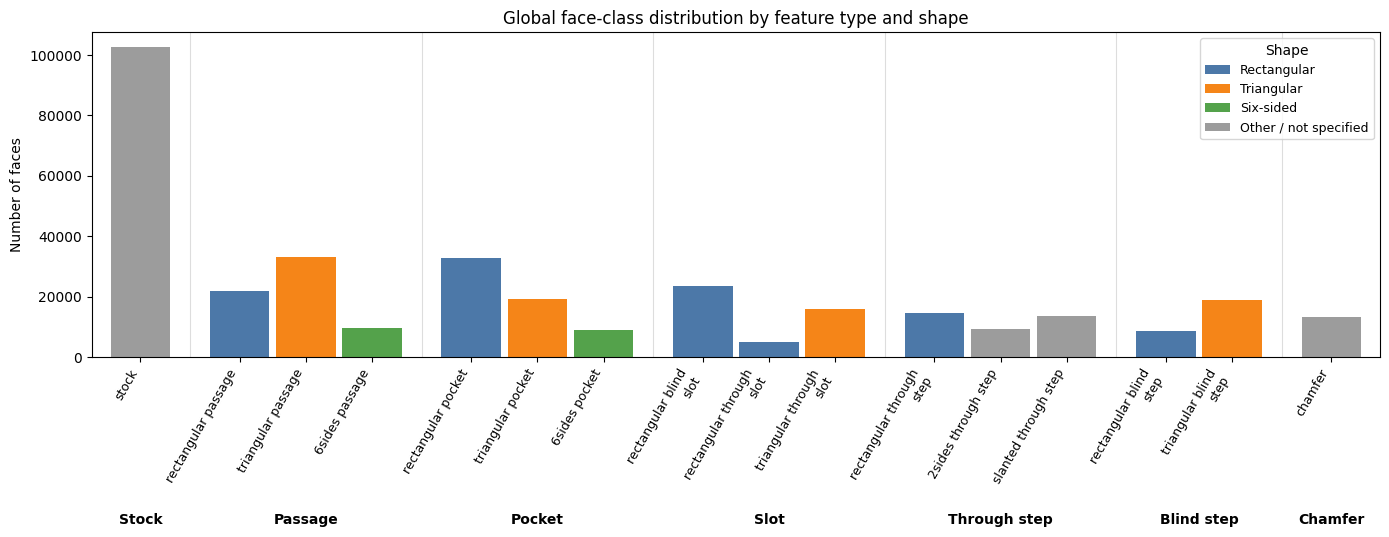

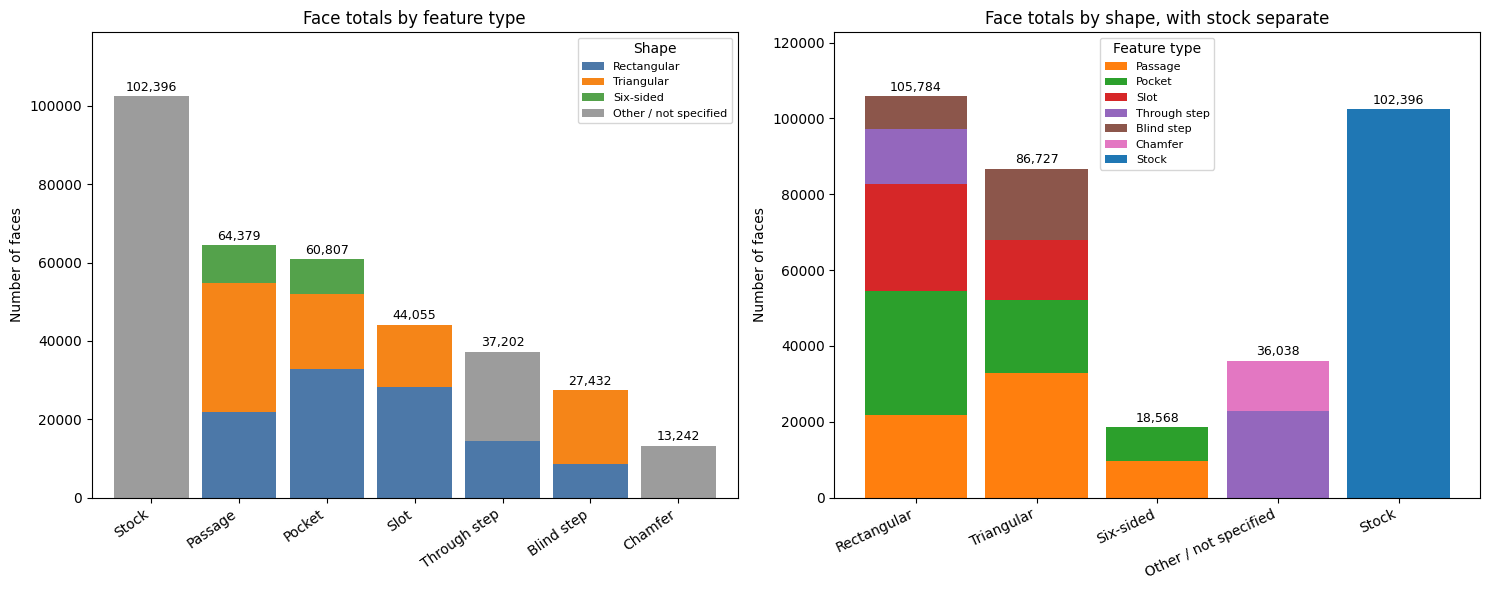

In [2]:
import textwrap
from matplotlib.patches import Patch

class_counts = faces["label"].value_counts().reindex(class_order)
class_table = class_counts.to_frame("Faces")
class_table["Percent"] = 100 * class_counts / class_counts.sum()

# Separate feature type, profile shape, and through/blind extent.
def class_attributes(label):
    words = label.split("_")
    feature_type = words[-1].capitalize()
    if words[0] == "rectangular":
        shape = "Rectangular"
    elif words[0] == "triangular":
        shape = "Triangular"
    elif words[0] == "6sides":
        shape = "Six-sided"
    else:
        shape = "Other / not specified"
    extent = "Through" if "through" in words else "Blind" if "blind" in words else ""
    if feature_type == "Step":
        feature_type = f"{extent} step"
    # Keep the entire original class name; wrap only for readability.
    tick = label.replace("_", " ")
    tick = "\n".join(textwrap.wrap(tick, width=20))
    return feature_type, shape, extent, tick

attributes = pd.DataFrame(
    [class_attributes(label) for label in class_counts.index],
    index=class_counts.index, columns=["Feature type", "Shape", "Extent", "Tick"]
)
class_table = attributes[["Feature type", "Shape", "Extent"]].join(class_table)
display(class_table)

shape_order = ["Rectangular", "Triangular", "Six-sided", "Other / not specified"]

family_totals = class_table.groupby("Feature type", sort=False)["Faces"].sum().sort_values(ascending=False)
plot_order, positions, group_centres = [], [], []
position = 0
for family in family_totals.index:
    labels = class_table[class_table["Feature type"] == family].index.tolist()
    labels.sort(key=lambda label: (shape_order.index(attributes.loc[label, "Shape"]), label))
    start = position
    for label in labels:
        plot_order.append(label)
        positions.append(position)
        position += 1
    group_centres.append((family, (start + position - 1) / 2))
    position += 0.5

shape_colours = {"Rectangular": "#4c78a8", "Triangular": "#f58518",
                 "Six-sided": "#54a24b", "Other / not specified": "#9c9c9c"}
bar_colours = [shape_colours[attributes.loc[label, "Shape"]] for label in plot_order]

def plot_class_groups(ax, values, title, ylabel):
    ax.bar(positions, values.reindex(plot_order), width=0.9, color=bar_colours)
    ax.set_xticks(positions, [attributes.loc[label, "Tick"] for label in plot_order], rotation=60, ha="right", fontsize=9)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.margins(x=0.015)
    for family, centre in group_centres:
        ax.text(centre, -0.48, family, transform=ax.get_xaxis_transform(), ha="center", va="top", fontweight="bold")
    for j in range(1, len(group_centres)):
        previous = family_totals.index[j - 1]
        left = max(pos for label, pos in zip(plot_order, positions) if attributes.loc[label, "Feature type"] == previous)
        ax.axvline(left + 0.75, color="#dddddd", linewidth=0.8)

fig, ax = plt.subplots(figsize=(14, 6.5))
plot_class_groups(ax, class_counts, "Global face-class distribution by feature type and shape", "Number of faces")
ax.legend(handles=[Patch(facecolor=colour, label=shape) for shape, colour in shape_colours.items()], title="Shape", fontsize=9)
fig.subplots_adjust(bottom=0.40, top=0.9, left=0.07, right=0.99)
plt.show()
# Show totals across both grouping dimensions as stacked bars.
feature_shape_counts = class_table.pivot_table(
    index="Feature type", columns="Shape", values="Faces",
    aggfunc="sum", fill_value=0
).reindex(index=family_totals.index, columns=shape_order, fill_value=0)
assert feature_shape_counts.to_numpy().sum() == class_counts.sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
feature_shape_counts.plot.bar(
    stacked=True, width=0.85, ax=axes[0],
    color=[shape_colours[shape] for shape in shape_order],
    title="Face totals by feature type", ylabel="Number of faces", rot=35
)
axes[0].legend(title="Shape", fontsize=8)

feature_colours = plt.get_cmap("tab10").colors[:len(family_totals)]
# Show stock as a separate bar, rather than as an unspecified shape.
shape_feature_counts = feature_shape_counts.drop(index="Stock").T
shape_feature_counts["Stock"] = 0
shape_feature_counts.loc["Stock"] = 0
shape_feature_counts.loc["Stock", "Stock"] = feature_shape_counts.loc["Stock"].sum()
feature_palette = dict(zip(family_totals.index, feature_colours))
shape_feature_counts.plot.bar(
    stacked=True, width=0.85, ax=axes[1],
    color=[feature_palette[family] for family in shape_feature_counts.columns],
    title="Face totals by shape, with stock separate", ylabel="Number of faces", rot=25
)
axes[1].legend(title="Feature type", fontsize=8)
for ax, totals in zip(axes, [feature_shape_counts.sum(axis=1), shape_feature_counts.sum(axis=1)]):
    for x, total in enumerate(totals):
        ax.annotate(f"{total:,}", (x, total), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=9)
    ax.set_ylim(0, totals.max() * 1.16)
    ax.set_xlabel("")
    plt.setp(ax.get_xticklabels(), ha="right")
fig.tight_layout()
plt.show()


**Analysis**

<!-- To be filled in after reviewing the results. -->


### Number of classes per model

Report summary statistics and plot the distribution of the number of distinct face classes in each model.


,count,mean,std,min,25%,50%,75%,max
Distinct classes per model,15461.0,4.649441,0.905923,2.0,4.0,5.0,5.0,6.0


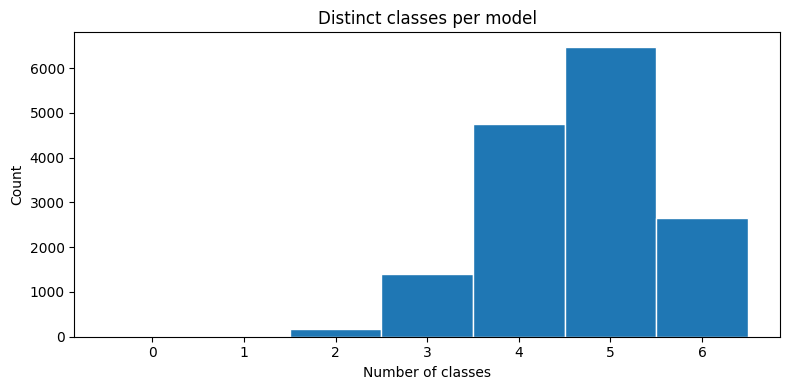

In [3]:
display(models["classes"].describe().to_frame("Distinct classes per model").T)
histogram(models["classes"], "Distinct classes per model", "Number of classes", bins=np.arange(models["classes"].max() + 2) - 0.5)

**Analysis**

<!-- To be filled in after reviewing the results. -->


### Stock-class proportion

Report the stock-class proportion across all faces and its distribution across individual models. Show the global proportion and a histogram of per-model proportions.


,Faces,Percent
Stock,102396,29.296764
Other classes,247117,70.703236


,count,mean,std,min,25%,50%,75%,max
Stock fraction per model,15461.0,0.309968,0.084876,0.101695,0.25,0.3,0.352941,0.75


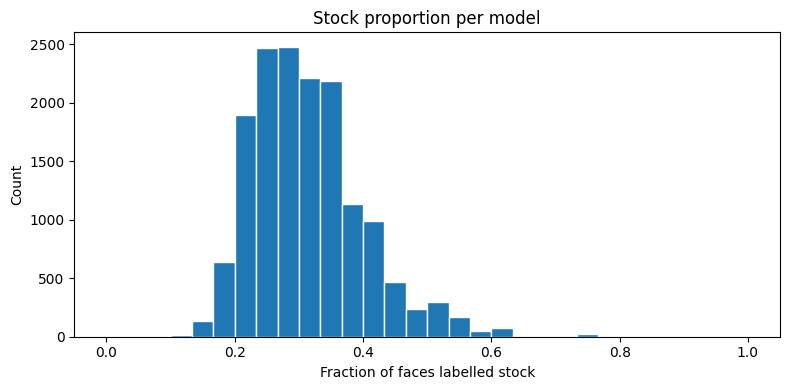

In [4]:
stock_total = models["stock_faces"].sum()
display(pd.DataFrame({"Faces": [stock_total, len(faces) - stock_total]}, index=["Stock", "Other classes"]).assign(Percent=lambda x: 100 * x["Faces"] / len(faces)))
display(models["stock_fraction"].describe().to_frame("Stock fraction per model").T)
histogram(models["stock_fraction"], "Stock proportion per model", "Fraction of faces labelled stock", bins=np.linspace(0, 1, 31))

**Analysis**

<!-- To be filled in after reviewing the results. -->


### Class distribution across splits

Tabulate raw face counts for the training, validation, and test sets. Plot within-split percentages in one facet per split, sharing the class axis, percentage scale, and shape colours.


split,train,validation,test
label,,,
stock,61389,20449,20558
triangular_passage,19859,6804,6278
rectangular_pocket,19705,6804,6216
rectangular_blind_slot,14025,4645,4670
rectangular_passage,13077,4390,4325
triangular_pocket,11556,3816,3788
triangular_blind_step,11356,3828,3572
triangular_through_slot,9605,2985,3280
rectangular_through_step,8508,2883,3015


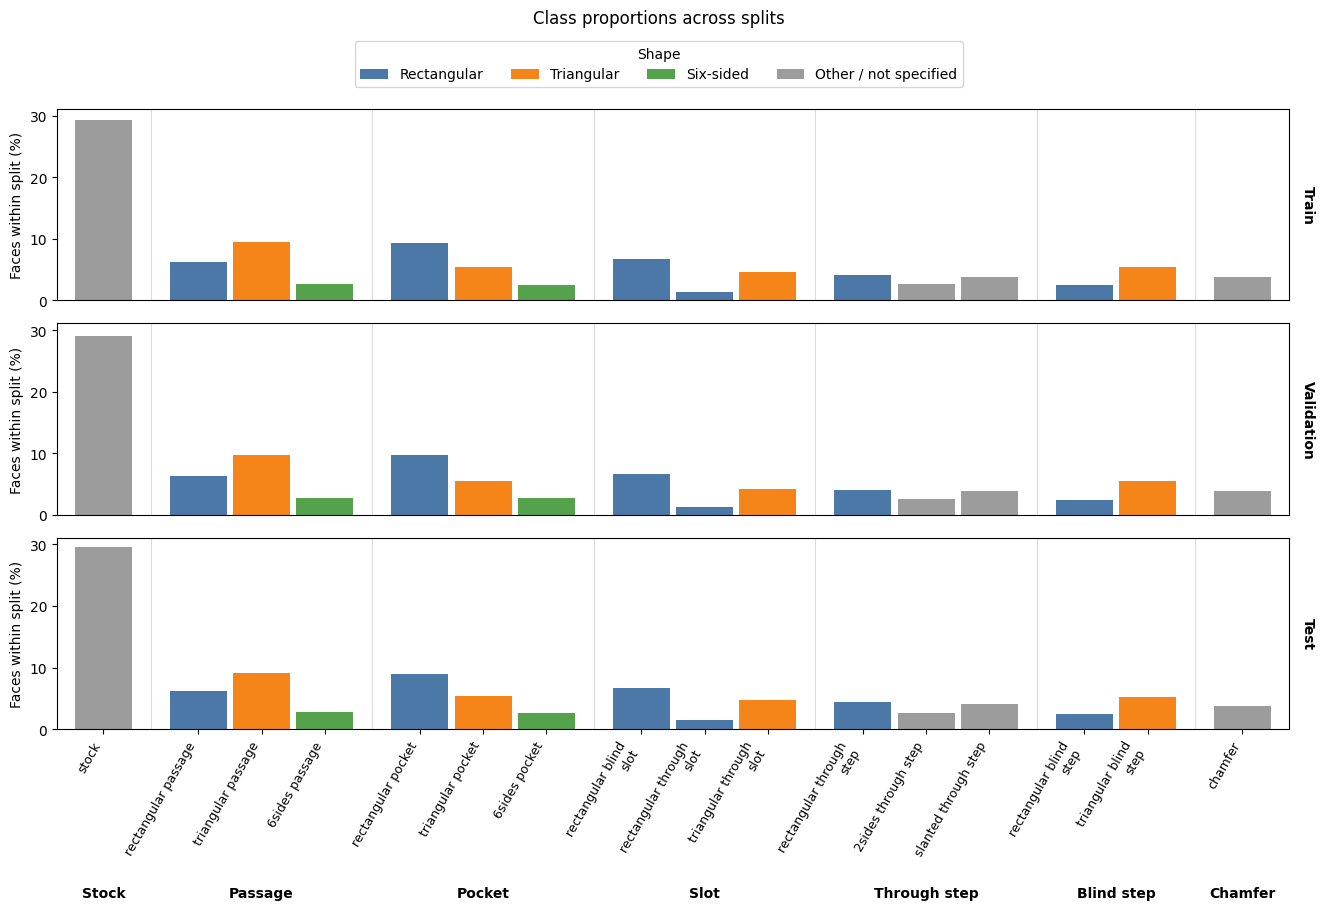

In [5]:
split_counts = pd.crosstab(faces["label"], faces["split"]).reindex(index=class_order, columns=list(splits), fill_value=0)
split_percent = split_counts.div(split_counts.sum(axis=0), axis=1) * 100
# Raw counts in the table; percentages in the chart.
display(split_counts)

# One facet per split, sharing the class axis and percentage scale.
fig, axes = plt.subplots(len(splits), 1, figsize=(14, 10),
                         sharex=True, sharey=True, squeeze=False)
for row, (ax, split) in enumerate(zip(axes[:, 0], splits)):
    plot_class_groups(ax, split_percent[split], "", "Faces within split (%)")
    ax.text(1.01, 0.5, split.capitalize(), transform=ax.transAxes,
            rotation=270, ha="left", va="center", fontweight="bold")
    if row < len(splits) - 1:
        ax.tick_params(axis="x", bottom=False, labelbottom=False)
        for text in list(ax.texts):
            if text.get_text() in family_totals.index:
                text.remove()
    else:
        for text in ax.texts:
            if text.get_text() in family_totals.index:
                text.set_position((text.get_position()[0], -0.82))
fig.suptitle("Class proportions across splits", y=0.99)
fig.legend(handles=[Patch(facecolor=colour, label=shape) for shape, colour in shape_colours.items()],
           loc="upper center", bbox_to_anchor=(0.5, 0.965), ncol=4, title="Shape")
fig.subplots_adjust(bottom=0.27, top=0.89, hspace=0.12, left=0.07, right=0.95)
plt.show()


**Analysis**

<!-- To be filled in after reviewing the results. -->


## Geometry


### Valid samples per face and edge

Report summary statistics for in-mask samples per face. Edge grids have six channels (XYZ and tangent), with no validity mask, so report their total sample count.


In [6]:
display(faces["valid_samples"].describe().to_frame("In-mask samples per face").T)
display(edges["samples"].describe().to_frame("Samples per edge (no mask channel)").T)


,count,mean,std,min,25%,50%,75%,max
In-mask samples per face,349513.0,92.834255,13.790373,17.0,91.0,100.0,100.0,100.0


,count,mean,std,min,25%,50%,75%,max
Samples per edge (no mask channel),927376.0,10.0,0.0,10.0,10.0,10.0,10.0,10.0


**Analysis**

<!-- To be filled in after reviewing the results. -->


### Geometric span and bounding boxes

Compute coordinate spans from valid samples for each face and edge. Report and plot the shortest non-zero dimension and the longest dimension, keeping face and edge results separate.


Mean face bounding-box spans by class (normalized coordinates)


Mean shortest non-zero span  \
Feature type Class                                                   
Stock        stock                                        1.540789   
Passage      rectangular_passage                          0.516924   
             triangular_passage                           0.086493   
             6sides_passage                               0.255227   
Pocket       rectangular_pocket                           0.112928   
             triangular_pocket                            0.491426   
             6sides_pocket                                0.484133   
Slot         rectangular_blind_slot                       0.422790   
             rectangular_through_slot                     0.497333   
             triangular_through_slot                      0.148359   
Through step rectangular_through_step                     0.675921   
             2sides_through_step                          0.801794   
             slanted_through_step                         0.401487   
Blind step   rectangular_blind_step                       0.509355   
             triangular_blind_step                        0.177852   
Chamfer      chamfer                                      0.509935   

                                       Mean longest span  
Feature type Class                                        
Stock        stock                              1.998355  
Passage      rectangular_passage                1.732596  
             triangular_passage                 1.705156  
             6sides_passage                     2.000000  
Pocket       rectangular_pocket                 0.714301  
             triangular_pocket                  0.896509  
             6sides_pocket                      0.987313  
Slot         rectangular_blind_slot             0.776614  
             rectangular_through_slot           1.980458  
             triangular_through_slot            1.791861  
Through step rectangular_through_step           2.000000  
             2sides_through_step                2.000000  
             slanted_through_step               1.394288  
Blind step   rectangular_blind_step             2.000000  
             triangular_blind_step              0.695943  
Chamfer      chamfer                            0.911046

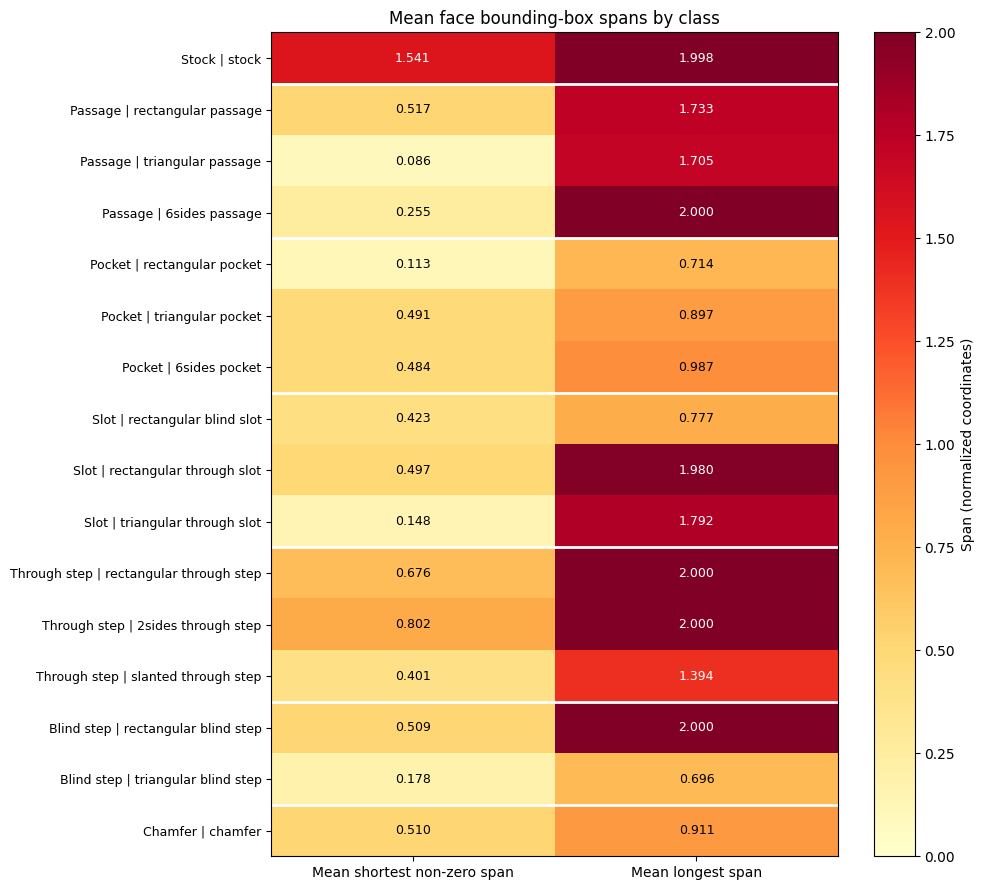

Face,count,mean,std,min,25%,50%,75%,max
shortest_span,349513.0,0.696707,0.673641,0.000006,0.199999,0.4,1.075952,2.0
longest_span,349513.0,1.522200,0.631180,0.008997,0.907664,2.0,2.000000,2.0


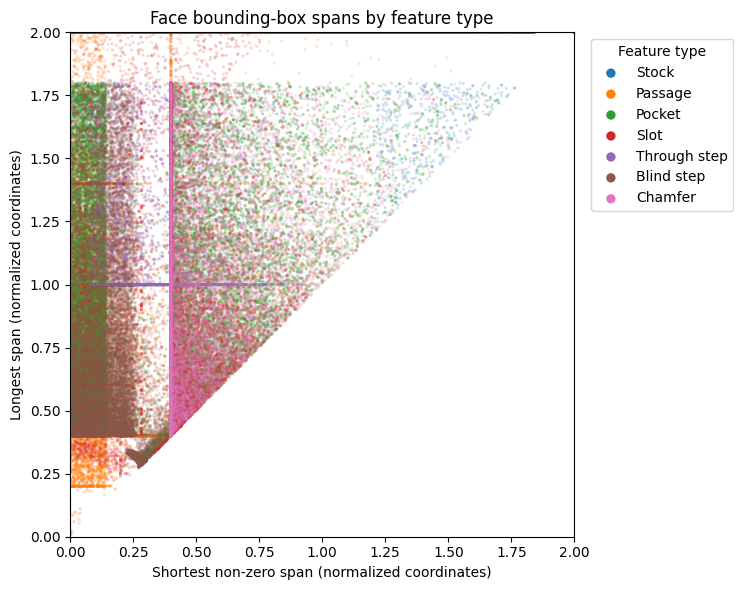

Edge,count,mean,std,min,25%,50%,75%,max
shortest_span,927376.0,0.836605,0.708796,0.000001,0.242044,0.536418,1.464900,2.0
longest_span,927376.0,0.911362,0.676893,0.000014,0.400000,0.622837,1.545027,2.0


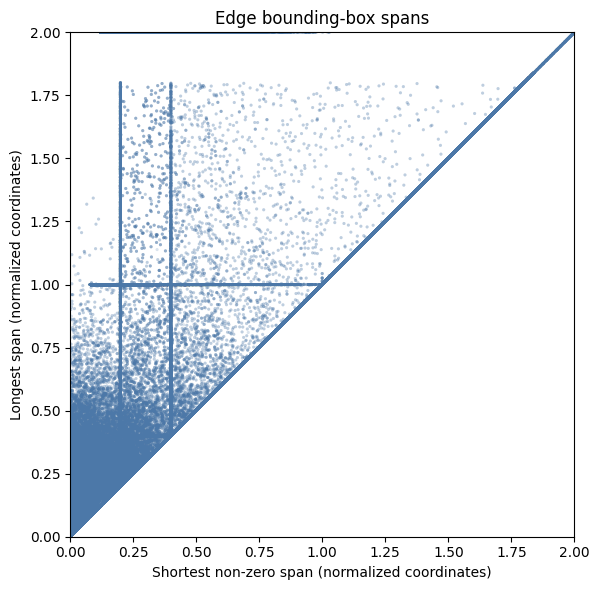

In [7]:
# Per-class face means, grouped by feature type in the chart order.
mean_face_spans = faces.groupby("label")[["shortest_span", "longest_span"]].mean().reindex(plot_order)
mean_face_spans = mean_face_spans.rename(columns={
    "shortest_span": "Mean shortest non-zero span",
    "longest_span": "Mean longest span"
})
mean_face_spans.insert(0, "Feature type", attributes.loc[plot_order, "Feature type"])
mean_face_spans.index.name = "Class"
mean_face_spans = mean_face_spans.reset_index().set_index(["Feature type", "Class"])
print("Mean face bounding-box spans by class (normalized coordinates)")
display(mean_face_spans)

# Shared colour scale preserves the comparison between shortest and longest spans.
fig, ax = plt.subplots(figsize=(10, 9))
image = ax.imshow(mean_face_spans.to_numpy(), cmap="YlOrRd", vmin=0, vmax=2, aspect="auto")
ax.set_xticks([0, 1], ["Mean shortest non-zero span", "Mean longest span"])
ax.set_yticks(range(len(mean_face_spans)),
              [f"{feature_type} | {label.replace('_', ' ')}" for feature_type, label in mean_face_spans.index], fontsize=9)
for row in range(len(mean_face_spans)):
    for col in range(2):
        value = mean_face_spans.iloc[row, col]
        ax.text(col, row, f"{value:.3f}", ha="center", va="center",
                color="white" if value > 1.3 else "black", fontsize=9)
for row in range(1, len(mean_face_spans)):
    if mean_face_spans.index[row][0] != mean_face_spans.index[row - 1][0]:
        ax.axhline(row - 0.5, color="white", linewidth=2)
ax.set_title("Mean face bounding-box spans by class")
fig.colorbar(image, ax=ax, label="Span (normalized coordinates)")
fig.tight_layout()
plt.show()

# Colour only the face scatter by feature type.
face_types = faces["label"].map(lambda label: class_attributes(label)[0])
type_order = list(family_totals.index)
type_colours = dict(zip(type_order, plt.get_cmap("tab10").colors))

for name, frame in [("Face", faces), ("Edge", edges)]:
    display(frame[["shortest_span", "longest_span"]].describe().rename_axis(name).T)
    fig, ax = plt.subplots(figsize=(8, 6))
    if name == "Face":
        for feature_type in type_order:
            selected = face_types == feature_type
            if selected.any():
                ax.scatter(frame.loc[selected, "shortest_span"], frame.loc[selected, "longest_span"],
                           label=feature_type, color=type_colours[feature_type],
                           s=5, alpha=0.2, edgecolors="none", rasterized=True)
        legend = ax.legend(title="Feature type", loc="upper left", bbox_to_anchor=(1.02, 1), markerscale=3)
        for handle in legend.legend_handles:
            handle.set_alpha(1)
        ax.set_title("Face bounding-box spans by feature type")
    else:
        ax.scatter(frame["shortest_span"], frame["longest_span"],
                   color="#4c78a8", s=5, alpha=0.2, edgecolors="none", rasterized=True)
        ax.set_title("Edge bounding-box spans")
    ax.set_xlabel("Shortest non-zero span (normalized coordinates)")
    ax.set_ylabel("Longest span (normalized coordinates)")
    ax.set_xlim(0, 2)
    ax.set_ylim(0, 2)
    ax.set_aspect("equal", adjustable="box")
    fig.tight_layout()
    plt.show()


**Analysis**

<!-- To be filled in after reviewing the results. -->


### Normal variation

Count flat and non-flat faces. A face is flat when the minimum dot product of its valid unit normals with the normalized mean normal is 1 (absolute floating-point tolerance: 1e-6). Report undefined normals separately if any are present.


In [8]:
# Flat means minimum alignment = 1, allowing floating-point tolerance.
flat_tolerance = 1e-6
normal_valid = faces["min_normal_dot"].notna()
flat = normal_valid & np.isclose(faces["min_normal_dot"], 1.0, atol=flat_tolerance, rtol=0)
nonflat = normal_valid & ~flat
print(f"Flat faces: {flat.sum():,}")
print(f"Non-flat faces: {nonflat.sum():,}")
if (~normal_valid).any():
    print(f"Undefined normals: {(~normal_valid).sum():,}")


Flat faces: 349,513
Non-flat faces: 0


**Analysis**

<!-- To be filled in after reviewing the results. -->


### Face-local spans: plane projection and PCA

Use one valid unit normal per planar face to construct two perpendicular in-plane unit vectors. Centre the valid XYZ samples, project into this local 2D plane, rotate using 2D PCA, and measure the shortest and longest bounding-box spans. The normal's XYZ components are retained in `planar_faces` alongside each model and face index.

These coordinates preserve the dataset's normalized length units; they are not the CAD surface's original UV parameters. PCA is fitted to the valid sampled points and provides a simple orientation-dependent bounding rectangle in the face plane, rather than a guaranteed minimum-area rectangle. The previous global XYZ span results are retained. Projected plot limits include all points because a rotated span can exceed 2 even when each global coordinate lies in [-1, 1].


train: projected 9,277 models


validation: projected 3,090 models


test: projected 3,094 models


Faces: 349,513; undefined spans: 0


,count,mean,std,min,25%,50%,75%,max
pca_shortest_span,349513.0,0.836306,0.736934,0.001835,0.349227,0.439661,1.181265,2.828427
pca_longest_span,349513.0,1.622928,0.730662,0.009141,0.917991,2.000000,2.000484,2.828427


Mean PCA shortest span  \
Feature type Class                                              
Stock        stock                                   1.725783   
Passage      rectangular_passage                     0.528552   
             triangular_passage                      0.236029   
             6sides_passage                          0.839038   
Pocket       rectangular_pocket                      0.229597   
             triangular_pocket                       0.491426   
             6sides_pocket                           0.547257   
Slot         rectangular_blind_slot                  0.440093   
             rectangular_through_slot                0.720479   
             triangular_through_slot                 0.401789   
Through step rectangular_through_step                0.675921   
             2sides_through_step                     0.801794   
             slanted_through_step                    0.697650   
Blind step   rectangular_blind_step                  0.744931   
             triangular_blind_step                   0.342772   
Chamfer      chamfer                                 0.509958   

                                       Mean PCA longest span  
Feature type Class                                            
Stock        stock                                  2.317190  
Passage      rectangular_passage                    1.736340  
             triangular_passage                     1.707356  
             6sides_passage                         2.000000  
Pocket       rectangular_pocket                     0.718856  
             triangular_pocket                      0.896509  
             6sides_pocket                          1.109787  
Slot         rectangular_blind_slot                 0.777550  
             rectangular_through_slot               1.990175  
             triangular_through_slot                1.797094  
Through step rectangular_through_step               2.000000  
             2sides_through_step                    2.000000  
             slanted_through_step                   1.423888  
Blind step   rectangular_blind_step                 2.059716  
             triangular_blind_step                  0.700808  
Chamfer      chamfer                                0.911067

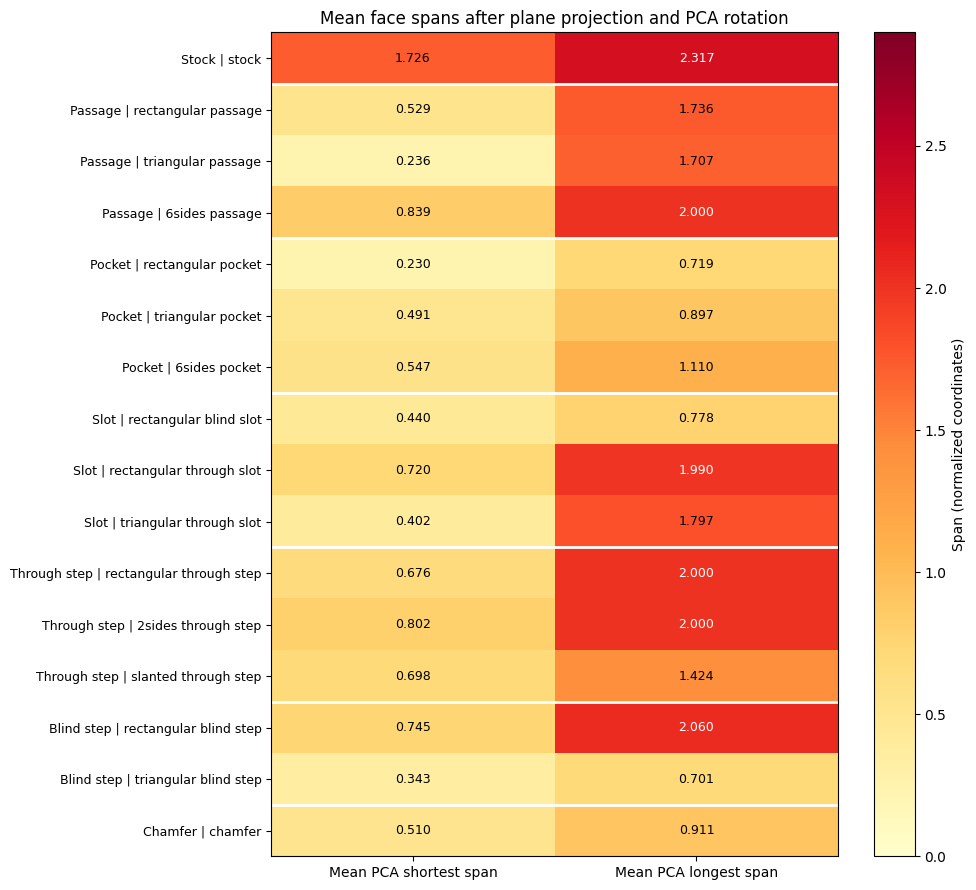

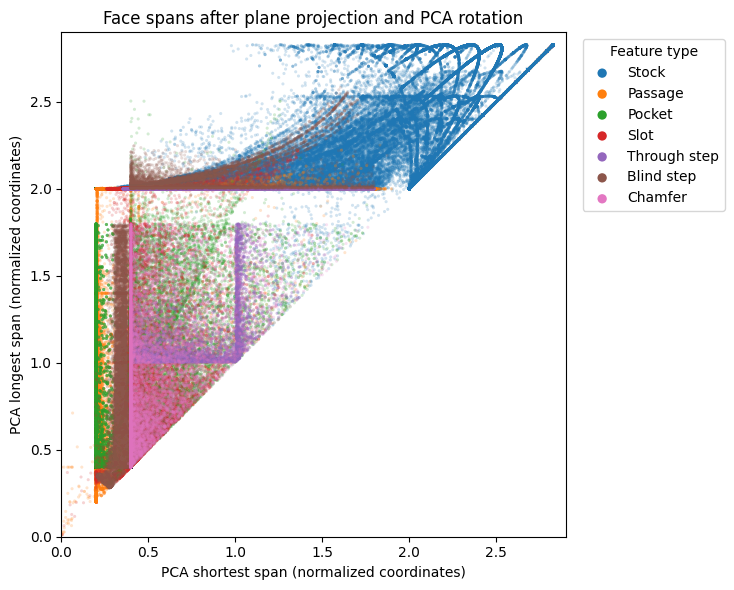

In [9]:
# Work in an orthonormal plane basis, then rotate the 2D samples using PCA.
planar_rows = []
for split, sample_ids in splits.items():
    for sample_id in sample_ids:
        sample = _load_sample(sample_id)
        for face_index, grid in enumerate(sample["graph"].ndata["x"].numpy()):
            valid = grid[..., 6] > 0.5
            points = grid[..., :3][valid].astype(np.float64)
            normals = grid[..., 3:6][valid].astype(np.float64)
            normal_lengths = np.linalg.norm(normals, axis=1)
            usable = normal_lengths > 1e-8
            normal = normals[usable][0] / normal_lengths[usable][0] if usable.any() else np.full(3, np.nan)
            shortest, longest = np.nan, np.nan
            if len(points) >= 2 and usable.any():
                # Pick a reference axis away from the normal to avoid a zero cross product.
                reference = np.eye(3)[np.argmin(np.abs(normal))]
                u = np.cross(normal, reference)
                u /= np.linalg.norm(u)
                v = np.cross(normal, u)
                centred = points - points.mean(axis=0)
                planar = centred @ np.column_stack([u, v])
                # Eigenvectors of the 2D covariance give the PCA rotation.
                covariance = planar.T @ planar / len(planar)
                eigenvalues, eigenvectors = np.linalg.eigh(covariance)
                rotated = planar @ eigenvectors[:, ::-1]
                spans = np.ptp(rotated, axis=0)
                shortest, longest = np.sort(spans)
            planar_rows.append({
                "model": sample_id, "split": split, "face_index": face_index,
                "label": sample["faces"][face_index]["segment"]["name"],
                "normal_x": normal[0], "normal_y": normal[1], "normal_z": normal[2],
                "pca_shortest_span": shortest, "pca_longest_span": longest
            })
    print(f"{split}: projected {len(sample_ids):,} models")

planar_faces = pd.DataFrame(planar_rows)
pca_columns = ["pca_shortest_span", "pca_longest_span"]
print(f"Faces: {len(planar_faces):,}; undefined spans: {planar_faces[pca_columns].isna().any(axis=1).sum():,}")
display(planar_faces[pca_columns].describe().T)

# Retain the same feature-type grouping and class order as the previous section.
mean_pca_spans = planar_faces.groupby("label")[pca_columns].mean().reindex(plot_order)
mean_pca_spans.columns = ["Mean PCA shortest span", "Mean PCA longest span"]
mean_pca_spans.insert(0, "Feature type", attributes.loc[plot_order, "Feature type"])
mean_pca_spans.index.name = "Class"
mean_pca_spans = mean_pca_spans.reset_index().set_index(["Feature type", "Class"])
display(mean_pca_spans)

# Projection preserves physical distances; rotated spans can exceed global-axis span 2.
pca_limit = max(2.0, np.ceil(planar_faces[pca_columns].max().max() * 10) / 10)
fig, ax = plt.subplots(figsize=(10, 9))
image = ax.imshow(mean_pca_spans.to_numpy(), cmap="YlOrRd", vmin=0, vmax=pca_limit, aspect="auto")
ax.set_xticks([0, 1], ["Mean PCA shortest span", "Mean PCA longest span"])
ax.set_yticks(range(len(mean_pca_spans)),
              [f"{feature_type} | {label.replace('_', ' ')}" for feature_type, label in mean_pca_spans.index], fontsize=9)
for row in range(len(mean_pca_spans)):
    for col in range(2):
        value = mean_pca_spans.iloc[row, col]
        ax.text(col, row, f"{value:.3f}", ha="center", va="center",
                color="white" if value > pca_limit * 0.65 else "black", fontsize=9)
for row in range(1, len(mean_pca_spans)):
    if mean_pca_spans.index[row][0] != mean_pca_spans.index[row - 1][0]:
        ax.axhline(row - 0.5, color="white", linewidth=2)
ax.set_title("Mean face spans after plane projection and PCA rotation")
fig.colorbar(image, ax=ax, label="Span (normalized coordinates)")
fig.tight_layout()
plt.show()

pca_types = planar_faces["label"].map(lambda label: class_attributes(label)[0])
pca_colours = dict(zip(family_totals.index, plt.get_cmap("tab10").colors))
fig, ax = plt.subplots(figsize=(8, 6))
for feature_type in family_totals.index:
    selected = pca_types == feature_type
    ax.scatter(planar_faces.loc[selected, "pca_shortest_span"],
               planar_faces.loc[selected, "pca_longest_span"],
               label=feature_type, color=pca_colours[feature_type],
               s=5, alpha=0.2, edgecolors="none", rasterized=True)
ax.set(xlim=(0, pca_limit), ylim=(0, pca_limit),
       xlabel="PCA shortest span (normalized coordinates)",
       ylabel="PCA longest span (normalized coordinates)",
       title="Face spans after plane projection and PCA rotation")
ax.set_aspect("equal", adjustable="box")
legend = ax.legend(title="Feature type", loc="upper left", bbox_to_anchor=(1.02, 1), markerscale=3)
for handle in legend.legend_handles:
    handle.set_alpha(1)
fig.tight_layout()
plt.show()


**Analysis**

<!-- To be filled in after reviewing the results. -->

## Graph


### Number of models per split

Tabulate the number of models in the training, validation, and test sets.


,Models
split,
train,9277
validation,3090
test,3094


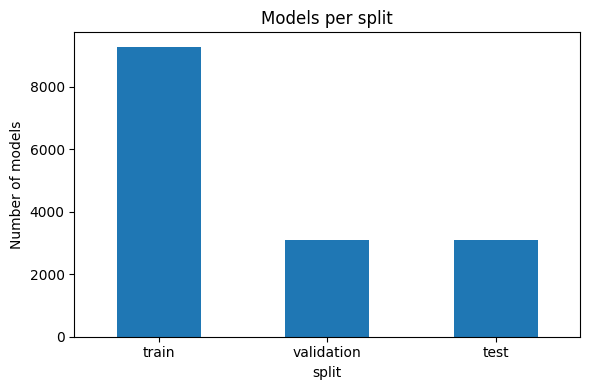

In [10]:
split_models = models["split"].value_counts().reindex(list(splits))
display(split_models.to_frame("Models"))
split_models.plot.bar(rot=0, figsize=(6, 4), ylabel="Number of models", title="Models per split")
plt.tight_layout()
plt.show()

**Analysis**

<!-- To be filled in after reviewing the results. -->


### Faces and edges per model

Report the mean, minimum, and maximum number of faces and edges per model, alongside their distributions. Edge counts refer to distinct B-rep edges; reverse directed entries are counted once.


,count,mean,std,min,25%,50%,75%,max
faces,15461.0,22.606106,5.286190,8.0,19.0,22.0,26.0,59.0
edges,15461.0,59.981631,16.081609,18.0,51.0,60.0,69.0,189.0


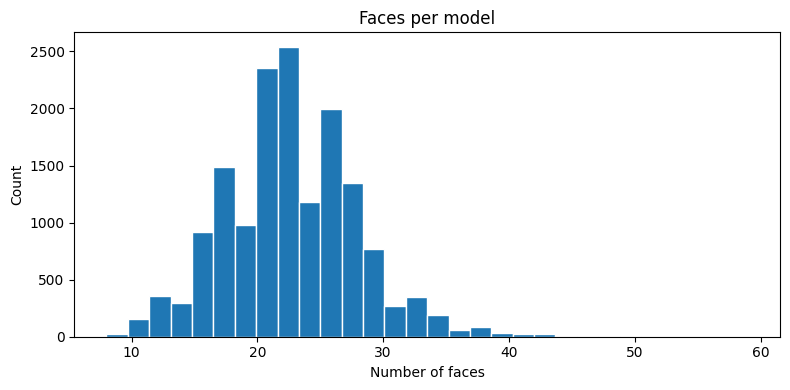

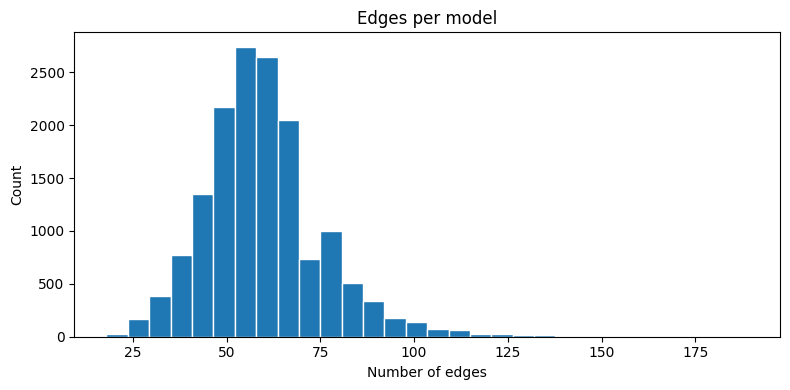

In [11]:
display(models[["faces", "edges"]].describe().T)
for column in ["faces", "edges"]:
    histogram(models[column], f"{column.capitalize()} per model", f"Number of {column}")

**Analysis**

<!-- To be filled in after reviewing the results. -->


### Node degree

Plot node degrees across all models and the maximum node degree within each model. Degree counts parallel edges separately. Reverse directed entries are not counted twice; the data pass checks that no self-loops are present.


,count,mean,std,min,25%,50%,75%,max
Face degree,349513.0,5.306675,2.785346,3.0,4.0,4.0,5.0,28.0


,count,mean,std,min,25%,50%,75%,max
Maximum degree per model,15461.0,13.34448,3.032119,5.0,11.0,13.0,15.0,28.0


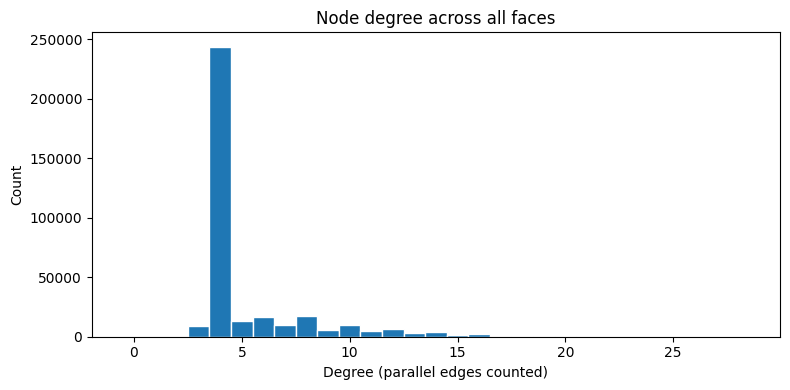

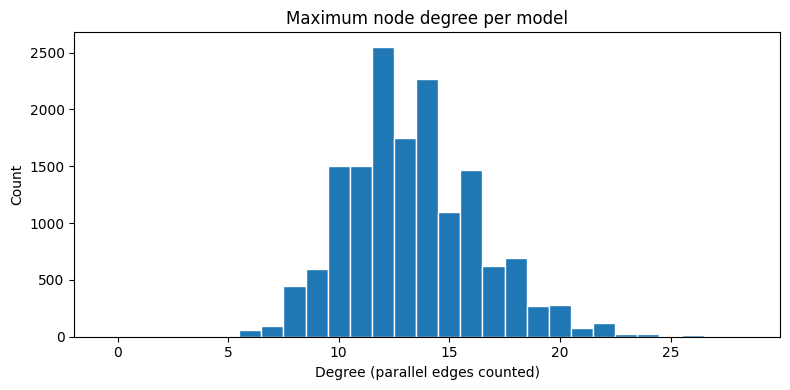

In [12]:
display(faces["degree"].describe().to_frame("Face degree").T)
display(models["max_degree"].describe().to_frame("Maximum degree per model").T)
for values, title in [(faces["degree"], "Node degree across all faces"), (models["max_degree"], "Maximum node degree per model")]:
    histogram(values, title, "Degree (parallel edges counted)", bins=np.arange(values.max() + 2) - 0.5)

**Analysis**

<!-- To be filled in after reviewing the results. -->


### Node degree by class

For non-stock faces, show each class percentage at degrees 3, 4, 5, 6, and 8, grouped by feature type. Heatmap colours use a shared 0–100% scale. Show stock separately with an integer-binned histogram. Degree counts parallel B-rep edges separately.

Only selected degree values are shown; row percentages need not sum to 100%. Each percentage uses all non-stock faces of that class as its denominator.


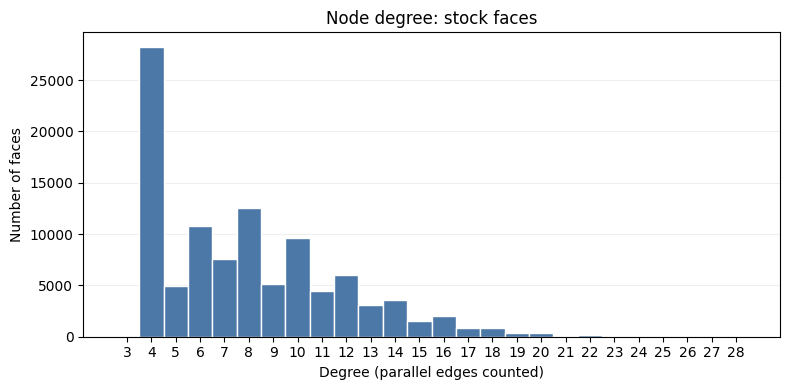

In [13]:
# Tally non-stock face degrees using the same class and feature-type order.
nonstock_order = [label for label in plot_order if label != "stock"]
nonstock_faces = faces.loc[faces["label"] != "stock"]
degree_tally = pd.crosstab(nonstock_faces["label"], nonstock_faces["degree"]).reindex(index=nonstock_order, fill_value=0)
class_totals = degree_tally.sum(axis=1)
degree_percent = degree_tally.reindex(columns=[3, 4, 5, 6, 8], fill_value=0).div(class_totals, axis=0) * 100
degree_percent.columns = ["Degree 3 (%)", "Degree 4 (%)", "Degree 5 (%)", "Degree 6 (%)", "Degree 8 (%)"]
degree_percent.insert(0, "Feature type", attributes.loc[nonstock_order, "Feature type"])
degree_percent.index.name = "Class"
degree_percent = degree_percent.reset_index().set_index(["Feature type", "Class"])
display(degree_percent.style.background_gradient(cmap="YlOrRd", vmin=0, vmax=100, axis=None).format("{:.2f}"))


stock_degrees = faces.loc[faces["label"] == "stock", "degree"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(stock_degrees, bins=np.arange(stock_degrees.min(), stock_degrees.max() + 2) - 0.5,
        color="#4c78a8", edgecolor="white")
ax.set(title="Node degree: stock faces", xlabel="Degree (parallel edges counted)", ylabel="Number of faces")
ax.set_xticks(np.arange(stock_degrees.min(), stock_degrees.max() + 1))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


**Analysis**

<!-- To be filled in after reviewing the results. -->

### Edge multiplicity

Tabulate the number of distinct edges connecting the same pair of faces. Report the count and percentage of models containing a face pair with multiplicity at least two. Reverse directed entries are counted once.


In [14]:
multiplicity_counts = pairs["multiplicity"].value_counts().sort_index()
display(multiplicity_counts.to_frame("Face pairs"))
display(pd.DataFrame({"Models": [models["has_parallel"].sum()], "Percent": [100 * models["has_parallel"].mean()]}, index=["Multiplicity at least 2"]))


,Face pairs
multiplicity,
1,915181
2,6003
3,63


,Models,Percent
Multiplicity at least 2,4661,30.146821


**Analysis**

<!-- To be filled in after reviewing the results. -->


### Shortest-path diameter

Compute the maximum shortest-path distance between faces for each model. Report summary statistics and plot its distribution.


,count,mean,std,min,25%,50%,75%,max
Shortest-path diameter,15461.0,3.952073,0.989318,2.0,3.0,4.0,5.0,6.0


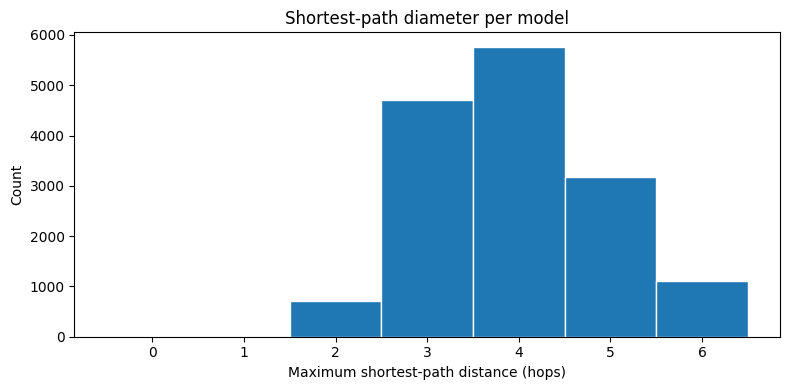

In [15]:
display(models["diameter"].describe().to_frame("Shortest-path diameter").T)
histogram(models["diameter"], "Shortest-path diameter per model", "Maximum shortest-path distance (hops)", bins=np.arange(models["diameter"].max() + 2) - 0.5)

**Analysis**

<!-- To be filled in after reviewing the results. -->


### Face reachability within N hops

For each starting face, count the other faces whose shortest-path distance is at most N, divided by the number of other faces in the same model. Plot the distribution of these percentages across all starting faces for each N, from one hop to the dataset's maximum diameter. The starting face is excluded; parallel edges are collapsed for distance calculations.

Each observation is a starting face, so models with more faces contribute more observations. Boxes show the median and interquartile range; whiskers use 1.5 times the interquartile range. Outlier markers are hidden for readability; all observations remain in the statistics. Models already fully covered remain at 100% for subsequent hops. Single-face models, if any, are excluded because they contain no other faces.


train: processed 9,277 models


validation: processed 3,090 models


test: processed 3,094 models


,count,mean,std,min,25%,50%,75%,max
Hops,,,,,,,,
1,349513.0,24.342499,13.600785,5.357143,16.000000,19.047619,26.666666,96.551727
2,349513.0,72.307724,21.873909,9.523809,56.521740,73.913040,93.333336,100.000000
3,349513.0,95.294357,10.568341,20.454546,95.454544,100.000000,100.000000,100.000000
4,349513.0,99.558868,2.426001,38.461540,100.000000,100.000000,100.000000,100.000000
5,349513.0,99.970528,0.365628,87.500000,100.000000,100.000000,100.000000,100.000000
6,349513.0,100.000000,0.000000,100.000000,100.000000,100.000000,100.000000,100.000000


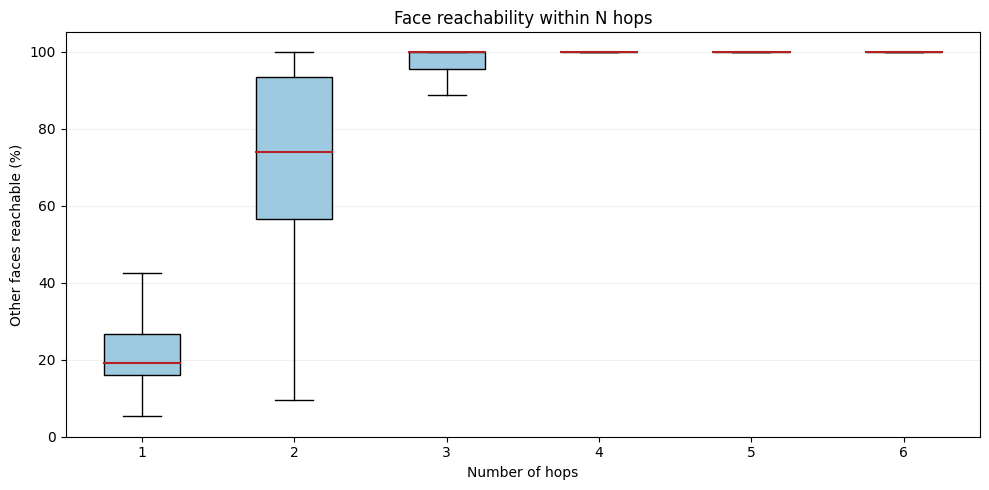

In [16]:
# Reachability is measured from each face, excluding the starting face.
# Parallel B-rep edges do not change shortest-path distances.
reachability_by_model = []
max_hops = 0
for split, sample_ids in splits.items():
    for sample_id in sample_ids:
        graph = _load_sample(sample_id)["graph"]
        src, dst = (x.numpy() for x in graph.edges())
        topology = nx.Graph()
        topology.add_nodes_from(range(graph.num_nodes()))
        topology.add_edges_from(zip(src.tolist(), dst.tolist()))
        n_faces = topology.number_of_nodes()
        if n_faces <= 1:
            continue  # No other faces: denominator would be zero.
        assert nx.is_connected(topology), sample_id
        model_diameter = 0
        cumulative = np.zeros((n_faces, n_faces), dtype=np.float32)
        for face, distances in nx.all_pairs_shortest_path_length(topology):
            distances = np.fromiter(distances.values(), dtype=int)
            counts = np.bincount(distances, minlength=n_faces)
            counts[0] = 0
            cumulative[face] = 100 * np.cumsum(counts) / (n_faces - 1)
            model_diameter = max(model_diameter, int(distances.max()))
        # Retain only columns up to this model's diameter; later hops remain 100%.
        reachability_by_model.append(cumulative[:, :model_diameter + 1])
        max_hops = max(max_hops, model_diameter)
    print(f"{split}: processed {len(sample_ids):,} models")

hop_counts = np.arange(1, max_hops + 1)
reachability = [np.concatenate([values[:, min(hop, values.shape[1] - 1)]
                               for values in reachability_by_model])
                for hop in hop_counts]
reachability_table = pd.DataFrame(
    {hop: pd.Series(values).describe() for hop, values in zip(hop_counts, reachability)}
).T
reachability_table.index.name = "Hops"
display(reachability_table)
assert all(np.all((values >= 0) & (values <= 100.00001)) for values in reachability)
assert np.allclose(reachability[-1], 100)

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(reachability, labels=hop_counts, showfliers=False,
           patch_artist=True, boxprops={"facecolor": "#9ecae1"},
           medianprops={"color": "#b22222", "linewidth": 1.5})
ax.set(xlabel="Number of hops", ylabel="Other faces reachable (%)",
       title="Face reachability within N hops", ylim=(0, 105))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


**Analysis**

<!-- To be filled in after reviewing the results. -->